# Demo 3 — Ba thuật toán và cận dưới
**Người nói 3 · 23:00–25:30 (2 phút 30)**

Cell 1, 2, 4 đọc dữ liệu tính sẵn bằng `scripts/make_data.py`; chỉ cell 3 chạy trực tiếp.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qsvt_demo import *
import qsvt_demo

plt.rcParams.update({"font.size": 13, "figure.figsize": (8, 3.6), "axes.grid": True})
reset_rng()
print(f"Qiskit {qiskit.__version__} | numpy {np.__version__} | seed {SEED}")
import csv

def read_csv(name):
    with open(DATA / name, encoding="utf-8") as fh:
        rows = list(csv.DictReader(fh))
    return {k: np.array([r[k] for r in rows]) for k in rows[0]}

Qiskit 2.6.2 | numpy 2.5.5 | seed 1234


## Cell 1 — E4: Grover gốc so với fixed-point search (Yoder–Low–Chuang)
Cùng số lần gọi oracle. Grover dao động và rơi khi $a$ khác giá trị thiết kế; fixed-point giữ trên $1-\delta^2$ với mọi $a\ge w$.

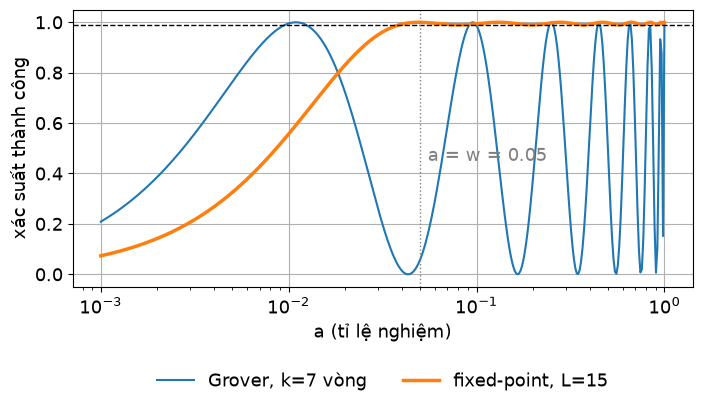

min fixed-point trên a ≥ w: 0.9900 (ngưỡng 0.99) PASS
kiểm tra công thức bằng mô phỏng 2D: sai số 1.92e-14


In [2]:
e4 = read_csv("e4_success.csv")
a = e4["a"].astype(float); grv = e4["grover"].astype(float); fp = e4["fixed_point"].astype(float)
w, delta, L, k = float(e4["w"][0]), float(e4["delta"][0]), int(e4["L"][0]), int(e4["k_grover"][0])
fig, ax = plt.subplots()
ax.semilogx(a, grv, lw=1.5, label=f"Grover, k={k} vòng")
ax.semilogx(a, fp, lw=2.5, label=f"fixed-point, L={L}")
ax.axhline(1 - delta**2, color="k", ls="--", lw=1); ax.axvline(w, color="gray", ls=":", lw=1)
ax.text(w * 1.1, 0.45, f"a = w = {w}", color="gray")
ax.set_xlabel("a (tỉ lệ nghiệm)"); ax.set_ylabel("xác suất thành công")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False); plt.show()
ok = np.all(fp[a >= w] >= 1 - delta**2 - 1e-12)
print(f"min fixed-point trên a ≥ w: {fp[a >= w].min():.4f} (ngưỡng {1 - delta**2})", verdict(ok))
print(f"kiểm tra công thức bằng mô phỏng 2D: sai số {e4['sv_check_err'][0]}")

## Cell 2 — E5: mô phỏng Hamiltonian, bậc QSVT so với số bước Trotter
$H$ ngẫu nhiên 8×8, $\|H\|=1$, mục tiêu $\|U-e^{-iHt}\|<10^{-3}$. Bậc QSVT = số lần gọi block-encoding.

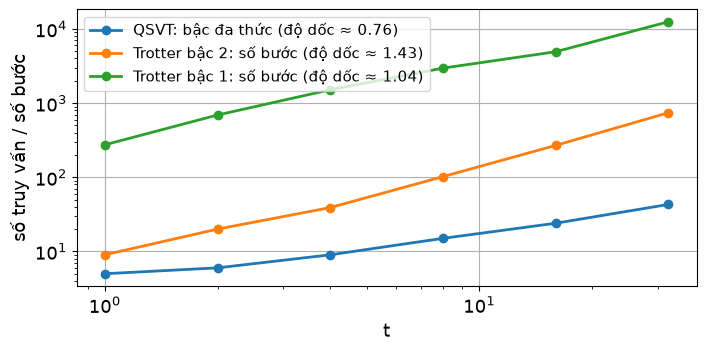

t     bậc cos(1e-6)  QSVT(1e-3)  Trotter1  Trotter2
1     6              5           274       9
2     8              6           691       20
4     12             9           1514      39
8     18             15          2965      102
16    30             24          4932      269
32    48             43          12525     742


In [3]:
e5 = read_csv("e5_degrees.csv")
t = e5["t"].astype(float)
cols = [("qsvt_degree_1e-3", "QSVT: bậc đa thức"), ("trotter2_steps", "Trotter bậc 2: số bước"),
        ("trotter1_steps", "Trotter bậc 1: số bước")]
fig, ax = plt.subplots()
for key, label in cols:
    y = e5[key].astype(float)
    slope = np.polyfit(np.log(t[-3:]), np.log(y[-3:]), 1)[0]
    ax.loglog(t, y, "o-", lw=2, label=f"{label} (độ dốc ≈ {slope:.2f})")
ax.set_xlabel("t"); ax.set_ylabel("số truy vấn / số bước"); ax.legend(loc="upper left", fontsize=11); plt.show()
print("t     bậc cos(1e-6)  QSVT(1e-3)  Trotter1  Trotter2")
for row in zip(*(e5[c] for c in ["t", "deg_cos_1e-6", "qsvt_degree_1e-3", "trotter1_steps", "trotter2_steps"])):
    print("{:<6}{:<15}{:<12}{:<10}{}".format(*row))

## Cell 3 — E6: hệ tuyến tính (chạy trực tiếp)
Hàm $1/x$ làm trơn $g(x)=\frac{1-e^{-(3\kappa x)^2}}{\kappa x}$ vượt 1 — không có bộ pha nào cho nó. Nhân 0.5 thì hợp lệ.

In [4]:
grid = np.linspace(-1, 1, 4001)
g = g_inv(8)
print(f"không nhân 0.5: max|g| = {np.max(np.abs(2 * g(grid))):.3f}", verdict(np.max(np.abs(2 * g(grid))) <= 1))
print(f"nhân 0.5:       max|g| = {np.max(np.abs(g(grid))):.3f}", verdict(np.max(np.abs(g(grid))) <= 1))
degs = [(k, min_degree(g_inv(k), 1e-3)) for k in [2, 4, 8, 16]]
for k, d in degs:
    print(f"kappa = {k:>2}: bậc = {d:>3}   bậc/kappa = {d / k:.1f}")

không nhân 0.5: max|g| = 1.914 FAIL
nhân 0.5:       max|g| = 0.957 PASS


kappa =  2: bậc =  27   bậc/kappa = 13.5
kappa =  4: bậc =  53   bậc/kappa = 13.2
kappa =  8: bậc = 107   bậc/kappa = 13.4
kappa = 16: bậc = 213   bậc/kappa = 13.3


In [5]:
e6 = read_csv("e6_degrees.csv")
print("kappa  n  bậc  sai số tương đối  xác suất hậu chọn")
for row in zip(*(e6[c] for c in ["kappa", "n", "degree", "rel_error", "p_success"])):
    print("{:<7}{:<3}{:<5}{:<18}{}".format(*row))

kappa  n  bậc  sai số tương đối  xác suất hậu chọn
2      4  27   1.71e-03          0.1284
2      8  27   8.47e-04          0.1596
4      4  53   1.29e-03          0.0946
4      8  53   1.57e-03          0.0960
8      4  107  1.20e-03          0.1604
8      8  107  1.98e-03          0.0646
16     4  213  1.79e-03          0.0497
16     8  213  1.70e-03          0.0365
32     4  427  1.45e-03          0.1305
32     8  427  2.13e-03          0.0214


## Cell 4 — E8: polynomial method cho OR
Bậc nhỏ nhất để có $q$ với $|q(0)|\le 1/3$, $|q(k)-1|\le 1/3$ ($k=1..N$), giải bằng `linprog` trong cơ sở Chebyshev. $d/\sqrt N$ gần như hằng số nên Grover tối ưu.

In [6]:
e8 = read_csv("e8_or_degree.csv")
print("N     bậc nhỏ nhất  d/sqrt(N)")
for row in zip(e8["N"], e8["min_degree"], e8["d_over_sqrtN"]):
    print("{:<6}{:<14}{}".format(*row))
r = e8["d_over_sqrtN"].astype(float)
print(verdict(r.max() / r.min() < 1.5))

N     bậc nhỏ nhất  d/sqrt(N)
16    3             0.750
64    6             0.750
256   11            0.688
PASS
